#Imports

In [1]:
import os
import random
import shutil
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pycocotools.coco import COCO

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from torchvision.models.segmentation import (
    deeplabv3_mobilenet_v3_large,
    DeepLabV3_MobileNet_V3_Large_Weights
)

from sklearn.metrics import classification_report

warnings.filterwarnings("ignore")

In [2]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Device: cuda
GPU: Tesla T4
CUDA: 12.8


#Download Data Set

In [3]:
import kagglehub

path = kagglehub.dataset_download(
    "amrgamal007/verycleanfarmers"
)

print("Path to dataset files:", path)

100%|██████████| 48.0M/48.0M [00:03<00:00, 15.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/amrgamal007/verycleanfarmers/versions/1


In [4]:
CONTENT_DATASET_PATH = "/content/verycleanfarmers"

if os.path.exists(CONTENT_DATASET_PATH):
    shutil.rmtree(CONTENT_DATASET_PATH)

shutil.copytree(
    path,
    CONTENT_DATASET_PATH
)

print(
    "Dataset copied to:",
    CONTENT_DATASET_PATH
)

Dataset copied to: /content/verycleanfarmers


In [5]:
DATASET_PATH = "/content/verycleanfarmers"

TRAIN_DIR = os.path.join(
    DATASET_PATH,
    "train"
)

VALID_DIR = os.path.join(
    DATASET_PATH,
    "valid"
)

TEST_DIR = os.path.join(
    DATASET_PATH,
    "test"
)

TRAIN_JSON = os.path.join(
    TRAIN_DIR,
    "_annotations.coco.json"
)

VALID_JSON = os.path.join(
    VALID_DIR,
    "_annotations.coco.json"
)

TEST_JSON = os.path.join(
    TEST_DIR,
    "_annotations.coco.json"
)

IMG_SIZE = (256, 256)

BATCH_SIZE = 8

EPOCHS_PHASE_1 = 15

EPOCHS_PHASE_2 = 35

NUM_WORKERS = 2

print("Train:", TRAIN_DIR)
print("Valid:", VALID_DIR)
print("Test :", TEST_DIR)

Train: /content/verycleanfarmers/train
Valid: /content/verycleanfarmers/valid
Test : /content/verycleanfarmers/test


#Load Data set

In [6]:
train_coco = COCO(TRAIN_JSON)

valid_coco = COCO(VALID_JSON)

test_coco = COCO(TEST_JSON)

train_ids = sorted(
    train_coco.getImgIds()
)

valid_ids = sorted(
    valid_coco.getImgIds()
)

test_ids = sorted(
    test_coco.getImgIds()
)

print(
    "Training Images:",
    len(train_ids)
)

print(
    "Validation Images:",
    len(valid_ids)
)

print(
    "Test Images:",
    len(test_ids)
)

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Training Images: 818
Validation Images: 74
Test Images: 37


In [7]:
class LeafDataset(Dataset):

    def __init__(
        self,
        coco,
        image_dir,
        image_ids,
        image_size=(256, 256)
    ):

        self.coco = coco
        self.image_dir = image_dir
        self.image_ids = image_ids
        self.image_size = image_size

    def __len__(self):

        return len(self.image_ids)

    def __getitem__(self, idx):

        image_id = self.image_ids[idx]

        info = self.coco.loadImgs(
            image_id
        )[0]

        image_path = os.path.join(
            self.image_dir,
            info["file_name"]
        )

        image = cv2.imread(
            image_path
        )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        mask = np.zeros(
            (
                info["height"],
                info["width"]
            ),
            dtype=np.uint8
        )

        ann_ids = self.coco.getAnnIds(
            imgIds=image_id
        )

        annotations = self.coco.loadAnns(
            ann_ids
        )

        for annotation in annotations:

            annotation_mask = (
                self.coco.annToMask(
                    annotation
                )
            )

            mask = np.maximum(
                mask,
                annotation_mask
            )

        image = cv2.resize(
            image,
            self.image_size,
            interpolation=cv2.INTER_LINEAR
        )

        mask = cv2.resize(
            mask,
            self.image_size,
            interpolation=cv2.INTER_NEAREST
        )

        image = (
            image.astype(np.float32)
            / 255.0
        )

        mean = np.array(
            [0.485, 0.456, 0.406],
            dtype=np.float32
        )

        std = np.array(
            [0.229, 0.224, 0.225],
            dtype=np.float32
        )

        image = (
            image - mean
        ) / std

        image = torch.tensor(
            image.transpose(2, 0, 1),
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        ).unsqueeze(0)

        return image, mask

In [8]:
train_dataset = LeafDataset(
    train_coco,
    TRAIN_DIR,
    train_ids,
    IMG_SIZE
)

valid_dataset = LeafDataset(
    valid_coco,
    VALID_DIR,
    valid_ids,
    IMG_SIZE
)

test_dataset = LeafDataset(
    test_coco,
    TEST_DIR,
    test_ids,
    IMG_SIZE
)

print(
    "Train Dataset:",
    len(train_dataset)
)

print(
    "Validation Dataset:",
    len(valid_dataset)
)

print(
    "Test Dataset:",
    len(test_dataset)
)

Train Dataset: 818
Validation Dataset: 74
Test Dataset: 37


In [9]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(
    "Train Batches:",
    len(train_loader)
)

print(
    "Validation Batches:",
    len(valid_loader)
)

print(
    "Test Batches:",
    len(test_loader)
)

Train Batches: 103
Validation Batches: 10
Test Batches: 5


#Visualization

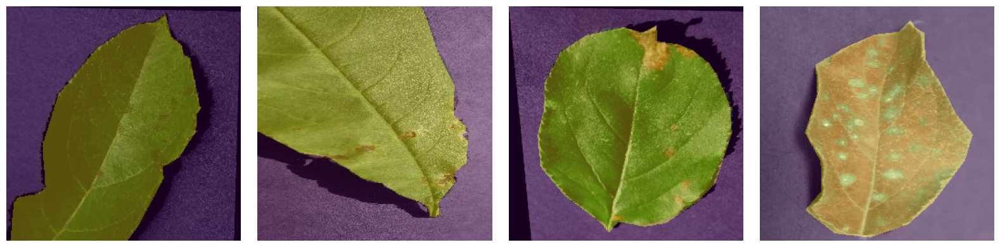

In [10]:
def denormalize_image(image):

    mean = np.array(
        [0.485, 0.456, 0.406]
    )

    std = np.array(
        [0.229, 0.224, 0.225]
    )

    image = (
        image * std
    ) + mean

    return np.clip(
        image,
        0,
        1
    )


fig, axes = plt.subplots(
    1,
    4,
    figsize=(16, 4)
)

for ax in axes:

    idx = np.random.randint(
        0,
        len(train_dataset)
    )

    image, mask = train_dataset[idx]

    image = image.permute(
        1, 2, 0
    ).numpy()

    image = denormalize_image(
        image
    )

    mask = mask.squeeze().numpy()

    ax.imshow(image)

    ax.imshow(
        mask,
        alpha=0.35
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

#Load DEEPLABV3 + MOBILE NET V3

In [11]:
weights = (
    DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT
)

model = deeplabv3_mobilenet_v3_large(
    weights=weights
)

model.classifier[-1] = nn.Conv2d(
    in_channels=256,
    out_channels=1,
    kernel_size=1
)

model = model.to(DEVICE)

print(model)

Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_mobilenet_v3_large-fc3c493d.pth


100%|██████████| 42.3M/42.3M [00:00<00:00, 200MB/s]


DeepLabV3(
  (backbone): IntermediateLayerGetter(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 64, kernel_size=(1, 1), stride

#Prepare Evaluation Metrics

In [12]:
def calculate_metrics(
    predictions,
    targets,
    smooth=1e-6
):

    probabilities = torch.sigmoid(
        predictions
    )

    predicted_masks = (
        probabilities > 0.5
    ).float()

    predicted_masks = (
        predicted_masks.view(-1)
    )

    targets = targets.view(-1)

    tp = (
        predicted_masks * targets
    ).sum()

    fp = (
        predicted_masks * (1 - targets)
    ).sum()

    fn = (
        (1 - predicted_masks) * targets
    ).sum()

    tn = (
        (1 - predicted_masks)
        * (1 - targets)
    ).sum()

    dice = (
        2 * tp + smooth
    ) / (
        2 * tp + fp + fn + smooth
    )

    iou = (
        tp + smooth
    ) / (
        tp + fp + fn + smooth
    )

    precision = (
        tp + smooth
    ) / (
        tp + fp + smooth
    )

    recall = (
        tp + smooth
    ) / (
        tp + fn + smooth
    )

    accuracy = (
        tp + tn + smooth
    ) / (
        tp + tn + fp + fn + smooth
    )

    return (
        dice.item(),
        iou.item(),
        precision.item(),
        recall.item(),
        accuracy.item()
    )

In [13]:
bce_loss = nn.BCEWithLogitsLoss()


def dice_loss(
    predictions,
    targets,
    smooth=1e-6
):

    probabilities = torch.sigmoid(
        predictions
    )

    probabilities = (
        probabilities.view(-1)
    )

    targets = targets.view(-1)

    intersection = (
        probabilities * targets
    ).sum()

    dice = (
        2 * intersection + smooth
    ) / (
        probabilities.sum()
        + targets.sum()
        + smooth
    )

    return 1 - dice


def segmentation_loss(
    predictions,
    targets
):

    return (
        bce_loss(
            predictions,
            targets
        )
        +
        dice_loss(
            predictions,
            targets
        )
    )

In [14]:
def train_one_epoch(
    model,
    loader,
    optimizer
):

    model.train()

    total_loss = 0
    total_dice = 0
    total_iou = 0
    total_precision = 0
    total_recall = 0
    total_accuracy = 0

    for images, masks in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(
            images
        )["out"]

        outputs = F.interpolate(
            outputs,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        loss = segmentation_loss(
            outputs,
            masks
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        metrics = calculate_metrics(
            outputs,
            masks
        )

        total_dice += metrics[0]
        total_iou += metrics[1]
        total_precision += metrics[2]
        total_recall += metrics[3]
        total_accuracy += metrics[4]

    n = len(loader)

    return {
        "loss": total_loss / n,
        "dice": total_dice / n,
        "iou": total_iou / n,
        "precision": total_precision / n,
        "recall": total_recall / n,
        "accuracy": total_accuracy / n
    }


def validate_one_epoch(
    model,
    loader
):

    model.eval()

    total_loss = 0
    total_dice = 0
    total_iou = 0
    total_precision = 0
    total_recall = 0
    total_accuracy = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            masks = masks.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(
                images
            )["out"]

            outputs = F.interpolate(
                outputs,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            loss = segmentation_loss(
                outputs,
                masks
            )

            total_loss += loss.item()

            metrics = calculate_metrics(
                outputs,
                masks
            )

            total_dice += metrics[0]
            total_iou += metrics[1]
            total_precision += metrics[2]
            total_recall += metrics[3]
            total_accuracy += metrics[4]

    n = len(loader)

    return {
        "loss": total_loss / n,
        "dice": total_dice / n,
        "iou": total_iou / n,
        "precision": total_precision / n,
        "recall": total_recall / n,
        "accuracy": total_accuracy / n
    }

#Transfer Learning

In [15]:
for param in model.backbone.parameters():
    param.requires_grad = False

optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=3e-4
)

best_val_dice = 0

history_phase1 = {
    "train_loss": [],
    "train_dice": [],
    "val_loss": [],
    "val_dice": []
}

In [16]:
for epoch in range(
    EPOCHS_PHASE_1
):

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer
    )

    val_metrics = validate_one_epoch(
        model,
        valid_loader
    )

    history_phase1[
        "train_loss"
    ].append(
        train_metrics["loss"]
    )

    history_phase1[
        "train_dice"
    ].append(
        train_metrics["dice"]
    )

    history_phase1[
        "val_loss"
    ].append(
        val_metrics["loss"]
    )

    history_phase1[
        "val_dice"
    ].append(
        val_metrics["dice"]
    )

    if val_metrics["dice"] > best_val_dice:

        best_val_dice = (
            val_metrics["dice"]
        )

        torch.save(
            model.state_dict(),
            "/content/best_phase1_model.pth"
        )

        print("Best Phase 1 model saved.")

    print(
        f"\nEpoch [{epoch+1}/{EPOCHS_PHASE_1}]"
    )

    print(
        f"Train Loss      : "
        f"{train_metrics['loss']:.4f}"
    )

    print(
        f"Train Dice      : "
        f"{train_metrics['dice']:.4f}"
    )

    print(
        f"Train IoU       : "
        f"{train_metrics['iou']:.4f}"
    )

    print(
        f"Train Precision : "
        f"{train_metrics['precision']:.4f}"
    )

    print(
        f"Train Recall    : "
        f"{train_metrics['recall']:.4f}"
    )

    print(
        f"Train Accuracy  : "
        f"{train_metrics['accuracy']:.4f}"
    )

    print("-----------------------------")

    print(
        f"Val Loss        : "
        f"{val_metrics['loss']:.4f}"
    )

    print(
        f"Val Dice        : "
        f"{val_metrics['dice']:.4f}"
    )

    print(
        f"Val IoU         : "
        f"{val_metrics['iou']:.4f}"
    )

    print(
        f"Val Precision   : "
        f"{val_metrics['precision']:.4f}"
    )

    print(
        f"Val Recall      : "
        f"{val_metrics['recall']:.4f}"
    )

    print(
        f"Val Accuracy    : "
        f"{val_metrics['accuracy']:.4f}"
    )

Best Phase 1 model saved.

Epoch [1/15]
Train Loss      : 0.3222
Train Dice      : 0.9166
Train IoU       : 0.8518
Train Precision : 0.9153
Train Recall    : 0.9219
Train Accuracy  : 0.9202
-----------------------------
Val Loss        : 0.2153
Val Dice        : 0.9466
Val IoU         : 0.8991
Val Precision   : 0.9742
Val Recall      : 0.9210
Val Accuracy    : 0.9467
Best Phase 1 model saved.

Epoch [2/15]
Train Loss      : 0.1878
Train Dice      : 0.9514
Train IoU       : 0.9076
Train Precision : 0.9515
Train Recall    : 0.9523
Train Accuracy  : 0.9530
-----------------------------
Val Loss        : 0.1424
Val Dice        : 0.9641
Val IoU         : 0.9312
Val Precision   : 0.9658
Val Recall      : 0.9626
Val Accuracy    : 0.9644

Epoch [3/15]
Train Loss      : 0.1593
Train Dice      : 0.9578
Train IoU       : 0.9192
Train Precision : 0.9567
Train Recall    : 0.9597
Train Accuracy  : 0.9592
-----------------------------
Val Loss        : 0.1543
Val Dice        : 0.9627
Val IoU         

In [17]:
model.load_state_dict(
    torch.load(
        "/content/best_phase1_model.pth",
        map_location=DEVICE
    )
)

print(
    "Best Phase 1 model loaded successfully."
)

Best Phase 1 model loaded successfully.


In [18]:
for param in model.backbone.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-5
)

best_val_dice = 0

patience = 5

counter = 0

history_phase2 = {
    "train_loss": [],
    "train_dice": [],
    "train_iou": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": []
}

In [19]:
for epoch in range(
    EPOCHS_PHASE_2
):

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer
    )

    val_metrics = validate_one_epoch(
        model,
        valid_loader
    )

    history_phase2[
        "train_loss"
    ].append(
        train_metrics["loss"]
    )

    history_phase2[
        "train_dice"
    ].append(
        train_metrics["dice"]
    )

    history_phase2[
        "train_iou"
    ].append(
        train_metrics["iou"]
    )

    history_phase2[
        "val_loss"
    ].append(
        val_metrics["loss"]
    )

    history_phase2[
        "val_dice"
    ].append(
        val_metrics["dice"]
    )

    history_phase2[
        "val_iou"
    ].append(
        val_metrics["iou"]
    )

    if val_metrics["dice"] > best_val_dice:

        best_val_dice = (
            val_metrics["dice"]
        )

        counter = 0

        torch.save(
            model.state_dict(),
            "/content/best_deeplab_mobilenet.pth"
        )

        print("Best Phase 2 model saved.")

    else:

        counter += 1

        print(
            f"No improvement "
            f"({counter}/{patience})"
        )

        if counter >= patience:

            print(
                "Early stopping triggered."
            )

            break

    print(
        f"\nEpoch [{epoch+1}/{EPOCHS_PHASE_2}]"
    )

    print(
        f"Train Loss      : "
        f"{train_metrics['loss']:.4f}"
    )

    print(
        f"Train Dice      : "
        f"{train_metrics['dice']:.4f}"
    )

    print(
        f"Train IoU       : "
        f"{train_metrics['iou']:.4f}"
    )

    print(
        f"Train Precision : "
        f"{train_metrics['precision']:.4f}"
    )

    print(
        f"Train Recall    : "
        f"{train_metrics['recall']:.4f}"
    )

    print(
        f"Train Accuracy  : "
        f"{train_metrics['accuracy']:.4f}"
    )

    print("-----------------------------")

    print(
        f"Val Loss        : "
        f"{val_metrics['loss']:.4f}"
    )

    print(
        f"Val Dice        : "
        f"{val_metrics['dice']:.4f}"
    )

    print(
        f"Val IoU         : "
        f"{val_metrics['iou']:.4f}"
    )

    print(
        f"Val Precision   : "
        f"{val_metrics['precision']:.4f}"
    )

    print(
        f"Val Recall      : "
        f"{val_metrics['recall']:.4f}"
    )

    print(
        f"Val Accuracy    : "
        f"{val_metrics['accuracy']:.4f}"
    )

Best Phase 2 model saved.

Epoch [1/35]
Train Loss      : 0.0968
Train Dice      : 0.9740
Train IoU       : 0.9493
Train Precision : 0.9735
Train Recall    : 0.9747
Train Accuracy  : 0.9752
-----------------------------
Val Loss        : 0.1066
Val Dice        : 0.9730
Val IoU         : 0.9476
Val Precision   : 0.9752
Val Recall      : 0.9708
Val Accuracy    : 0.9731
Best Phase 2 model saved.

Epoch [2/35]
Train Loss      : 0.0909
Train Dice      : 0.9756
Train IoU       : 0.9523
Train Precision : 0.9755
Train Recall    : 0.9757
Train Accuracy  : 0.9765
-----------------------------
Val Loss        : 0.1041
Val Dice        : 0.9734
Val IoU         : 0.9484
Val Precision   : 0.9766
Val Recall      : 0.9703
Val Accuracy    : 0.9735
Best Phase 2 model saved.

Epoch [3/35]
Train Loss      : 0.0878
Train Dice      : 0.9764
Train IoU       : 0.9539
Train Precision : 0.9761
Train Recall    : 0.9768
Train Accuracy  : 0.9774
-----------------------------
Val Loss        : 0.1010
Val Dice       

In [20]:
model.load_state_dict(
    torch.load(
        "/content/best_deeplab_mobilenet.pth",
        map_location=DEVICE
    )
)

model.eval()

print(
    "Best fine-tuned model loaded successfully."
)

Best fine-tuned model loaded successfully.


#Evaluation

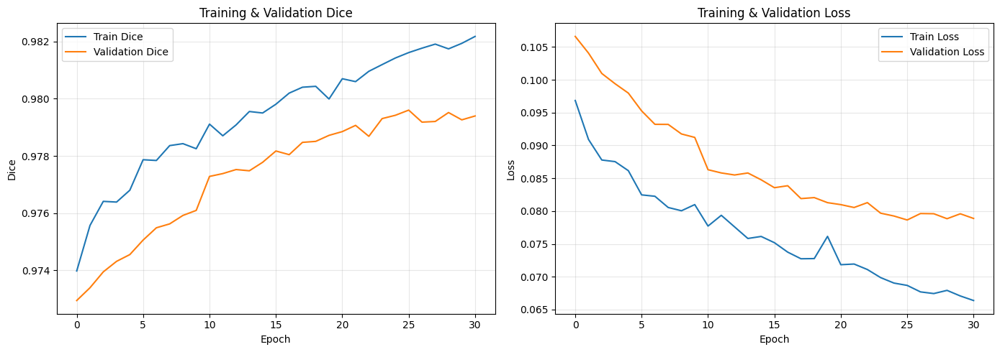

In [21]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    history_phase2["train_dice"],
    label="Train Dice"
)

axes[0].plot(
    history_phase2["val_dice"],
    label="Validation Dice"
)

axes[0].set_title(
    "Training & Validation Dice"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "Dice"
)

axes[0].legend()

axes[0].grid(
    alpha=0.3
)

axes[1].plot(
    history_phase2["train_loss"],
    label="Train Loss"
)

axes[1].plot(
    history_phase2["val_loss"],
    label="Validation Loss"
)

axes[1].set_title(
    "Training & Validation Loss"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Loss"
)

axes[1].legend()

axes[1].grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [22]:
test_metrics = validate_one_epoch(
    model,
    test_loader
)

print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print(
    f"Loss      : "
    f"{test_metrics['loss']:.4f}"
)

print(
    f"Dice      : "
    f"{test_metrics['dice']:.4f}"
)

print(
    f"IoU       : "
    f"{test_metrics['iou']:.4f}"
)

print(
    f"Precision : "
    f"{test_metrics['precision']:.4f}"
)

print(
    f"Recall    : "
    f"{test_metrics['recall']:.4f}"
)

print(
    f"Accuracy  : "
    f"{test_metrics['accuracy']:.4f}"
)

FINAL TEST RESULTS
Loss      : 0.0722
Dice      : 0.9807
IoU       : 0.9621
Precision : 0.9797
Recall    : 0.9817
Accuracy  : 0.9814


In [23]:
y_true = []

y_pred = []

model.eval()

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(DEVICE)

        outputs = model(
            images
        )["out"]

        outputs = F.interpolate(
            outputs,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        predictions = (
            torch.sigmoid(outputs)
            > 0.5
        )

        y_pred.extend(
            predictions
            .cpu()
            .numpy()
            .flatten()
        )

        y_true.extend(
            masks
            .numpy()
            .flatten()
        )

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Background",
            "Leaf"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

  Background     0.9825    0.9809    0.9817   1236055
        Leaf     0.9802    0.9819    0.9810   1188777

    accuracy                         0.9814   2424832
   macro avg     0.9814    0.9814    0.9814   2424832
weighted avg     0.9814    0.9814    0.9814   2424832



#Visualization

In [24]:
visualization_results = []

model.eval()

with torch.no_grad():

    for idx in range(
        len(test_dataset)
    ):

        image, gt_mask = (
            test_dataset[idx]
        )

        prediction = model(
            image.unsqueeze(0).to(DEVICE)
        )["out"]

        prediction = F.interpolate(
            prediction,
            size=gt_mask.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        pred_mask = (
            torch.sigmoid(
                prediction
            ) > 0.5
        ).float()

        image_np = denormalize_image(
            image
            .permute(1, 2, 0)
            .cpu()
            .numpy()
        )

        gt_np = (
            gt_mask
            .squeeze()
            .cpu()
            .numpy()
            .astype(np.uint8)
        )

        pred_np = (
            pred_mask
            .squeeze()
            .cpu()
            .numpy()
            .astype(np.uint8)
        )

        intersection = np.logical_and(
            pred_np,
            gt_np
        ).sum()

        dice = (
            2 * intersection + 1e-6
        ) / (
            pred_np.sum()
            + gt_np.sum()
            + 1e-6
        )

        gt_overlay = (
            image_np * 255
        ).astype(
            np.uint8
        ).copy()

        contours, _ = cv2.findContours(
            gt_np,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        cv2.drawContours(
            gt_overlay,
            contours,
            -1,
            (0, 255, 0),
            2
        )

        pred_overlay = (
            image_np * 255
        ).astype(
            np.uint8
        ).copy()

        contours, _ = cv2.findContours(
            pred_np,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        cv2.drawContours(
            pred_overlay,
            contours,
            -1,
            (255, 0, 0),
            2
        )

        pred_overlay[
            pred_np == 1
        ] = (
            pred_overlay[
                pred_np == 1
            ] * 0.6
            +
            np.array(
                [255, 0, 0]
            ) * 0.4
        ).astype(
            np.uint8
        )

        visualization_results.append({

            "dice": dice,

            "image": image_np,

            "gt": gt_overlay,

            "pred": pred_overlay

        })

visualization_results = sorted(
    visualization_results,
    key=lambda x: x["dice"]
)

print(
    "Total test images:",
    len(visualization_results)
)

Total test images: 37





In [25]:
NUM_IMAGES = len(
    visualization_results
)

plt.figure(
    figsize=(
        18,
        NUM_IMAGES * 4.5
    )
)

for idx, sample in enumerate(
    visualization_results
):

    plt.subplot(
        NUM_IMAGES,
        3,
        idx * 3 + 1
    )

    plt.imshow(
        sample["image"]
    )

    plt.title(
        "Original"
    )

    plt.axis("off")

    plt.subplot(
        NUM_IMAGES,
        3,
        idx * 3 + 2
    )

    plt.imshow(
        sample["gt"]
    )

    plt.title(
        "Ground Truth"
    )

    plt.axis("off")

    plt.subplot(
        NUM_IMAGES,
        3,
        idx * 3 + 3
    )

    plt.imshow(
        sample["pred"]
    )

    plt.title(
        f"Prediction\n"
        f"Dice = {sample['dice']:.4f}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()